In [10]:
!pip install langchain-groq


In [11]:
from google.colab import userdata
groq_api_key=userdata.get("GROQ_API_KEY")
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
llm = ChatGroq(
    groq_api_key=groq_api_key,
    model="openai/gpt-oss-120b",
    temperature=0,
)

### **Pydantic LLm Schema** -for the node which will generate the list of task

In [19]:
from pydantic import BaseModel, Field
from typing import List,TypedDict,Literal

class llm_schema(BaseModel):
  funny_flag:Literal["funny","not funny"]=  Field(description="Decide if the joke is funny or not.")
  feedback:str=Field(description="If the joke is not funny, provide feedback on how to improve it.")
llm_with_schema=llm.with_structured_output(llm_schema)


## **Graph Schema**

In [13]:
class graph_schema(TypedDict):
  topic:str
  joke:str
  funny_flag:str
  feedback:str
  max_iterations:int




## **Creating Generator Node**

In [14]:
def generate_node(state:graph_schema) ->graph_schema:

  topic=state["topic"]

  # because we are generating our joke base on feedback
  if state['feedback']: # Not first iteration ,generate a joke based on feedback
    response=llm.invoke(f"please modify the following joke{state['joke']}based on the following feedback:{state['feedback']} ")
  else:# First iteration , generate a joke
    response=llm.invoke("create a joke about the following topic: "+topic)

  state['joke']=response.content
  return state


## **Evaluator Node**

In [15]:
from langchain_core.runnables import chain
# Now  evaluate the joke
def evaluate_node(state:graph_schema) ->graph_schema:
  joke=state['joke']
  iteration=state['max_iterations'] # we have to make iteration that we can't go 5 iteration
  prompt=ChatPromptTemplate.from_messages([
      ("system","You are a comedy critic.your job is to evaluate the following joke and provide feedback on how  to make it funnier."),
      ("user",f"Evaluate the following joke:{joke}\nRespond with 'funny'or 'not funny and provide feedback if it is not funny.")
  ])

  chain=prompt|llm_with_schema
  response=chain.invoke({"joke":joke})

  state['funny_flag']=response.funny_flag
  state['feedback']=response.feedback
  state['max_iterations']=iteration+1
  return state

## Conditional Edge Function -  between generator node and Evaluate node  you don't need to go evaluate node every node every time .you only go to the evaluate node if value of max_iterations is lessthen or equal to 5

In [16]:
def check_iteration(state:graph_schema) ->str:
  iteration=state['max_iterations']
  if iteration<=5 and state['funny_flag']!="funny":
    return "evaluate_node"
  else:
    return "end"

## Create  state graph

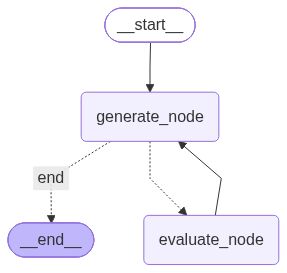

In [17]:
from langgraph.graph import StateGraph,START,END
graph=StateGraph(graph_schema)
graph.add_node("generate_node",generate_node)
graph.add_node("evaluate_node",evaluate_node)

graph.add_edge(START,"generate_node")
graph.add_conditional_edges("generate_node",check_iteration,{"evaluate_node":"evaluate_node","end":END})
graph.add_edge("evaluate_node","generate_node")
graph.add_edge("generate_node",END)

evaluator_graph=graph.compile()

from IPython.display import Image,display
Image(evaluator_graph.get_graph().draw_mermaid_png())

It go to the evaluate node only if the iteration are more than 5 otherwise it will not go to the evaluate node this will simple go to the generate node every time

## INVOKE GRAPH

In [18]:
for chunk in evaluator_graph.stream({
    "topic":"Cars",
    "joke":"",
    "funny_flag":"",
    "feedback":"",
    "max_iterations":0
},
stream_mode="updates"
):
  print(chunk)





{'generate_node': {'topic': 'Cars', 'joke': 'Why did the car apply for a job?\n\nBecause it wanted to *shift* gears in its career and finally stop *braking* its own potential! 🚗💼', 'funny_flag': '', 'feedback': '', 'max_iterations': 0}}
{'evaluate_node': {'topic': 'Cars', 'joke': 'Why did the car apply for a job?\n\nBecause it wanted to *shift* gears in its career and finally stop *braking* its own potential! 🚗💼', 'funny_flag': 'not funny', 'feedback': 'The joke leans heavily on car‑related puns, but the punchline feels a bit forced and predictable. To boost the humor, try tightening the setup for a sharper surprise, maybe by playing with the double meaning of "apply" (as in applying for a job and applying brakes). For example: "Why did the car send in a résumé? It heard the company was looking for someone who could really shift gears and stop stalling." This adds a bit more wordplay variety and a clearer twist. Also, consider trimming the emoji or using it for comedic timing rather th

BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is required, but model did not call a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': 'funny'}}